In [7]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:

import csv
data = pd.read_csv('/content/Day-14_dengue.csv', quoting=csv.QUOTE_NONE)

In [9]:
data.head()

,Name,Fever,Headache,JointPain,Bleeding,Dengue
0,Jeremy Long,0,0,1,1,1
1,Cassandra Glover,1,1,1,0,1
2,Aaron Adams MD,0,1,1,0,0
3,Elizabeth Thomas,0,1,0,1,1
4,Mathew Perez,0,0,1,0,1


In [10]:
data.tail()

,Name,Fever,Headache,JointPain,Bleeding,Dengue
999995,Edward May,1,1,1,1,1
999996,Sheri Patton,1,1,0,0,0
999997,Margaret Bailey,1,0,1,1,1
999998,Cristian Nelson,1,1,1,1,0
999999,Oscar Tucker,0,0,0,0,0


In [11]:
data.shape

(1000000, 6)

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   Name       1000000 non-null  object
 1   Fever      1000000 non-null  int64 
 2   Headache   1000000 non-null  int64 
 3   JointPain  1000000 non-null  int64 
 4   Bleeding   1000000 non-null  int64 
 5   Dengue     1000000 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 45.8+ MB


In [13]:
data.isnull().sum()

,0
Name,0
Fever,0
Headache,0
JointPain,0
Bleeding,0
Dengue,0


In [14]:
data.min(numeric_only=True)

,0
Fever,0
Headache,0
JointPain,0
Bleeding,0
Dengue,0


In [15]:
data.max(numeric_only=True)

,0
Fever,1
Headache,1
JointPain,1
Bleeding,1
Dengue,1


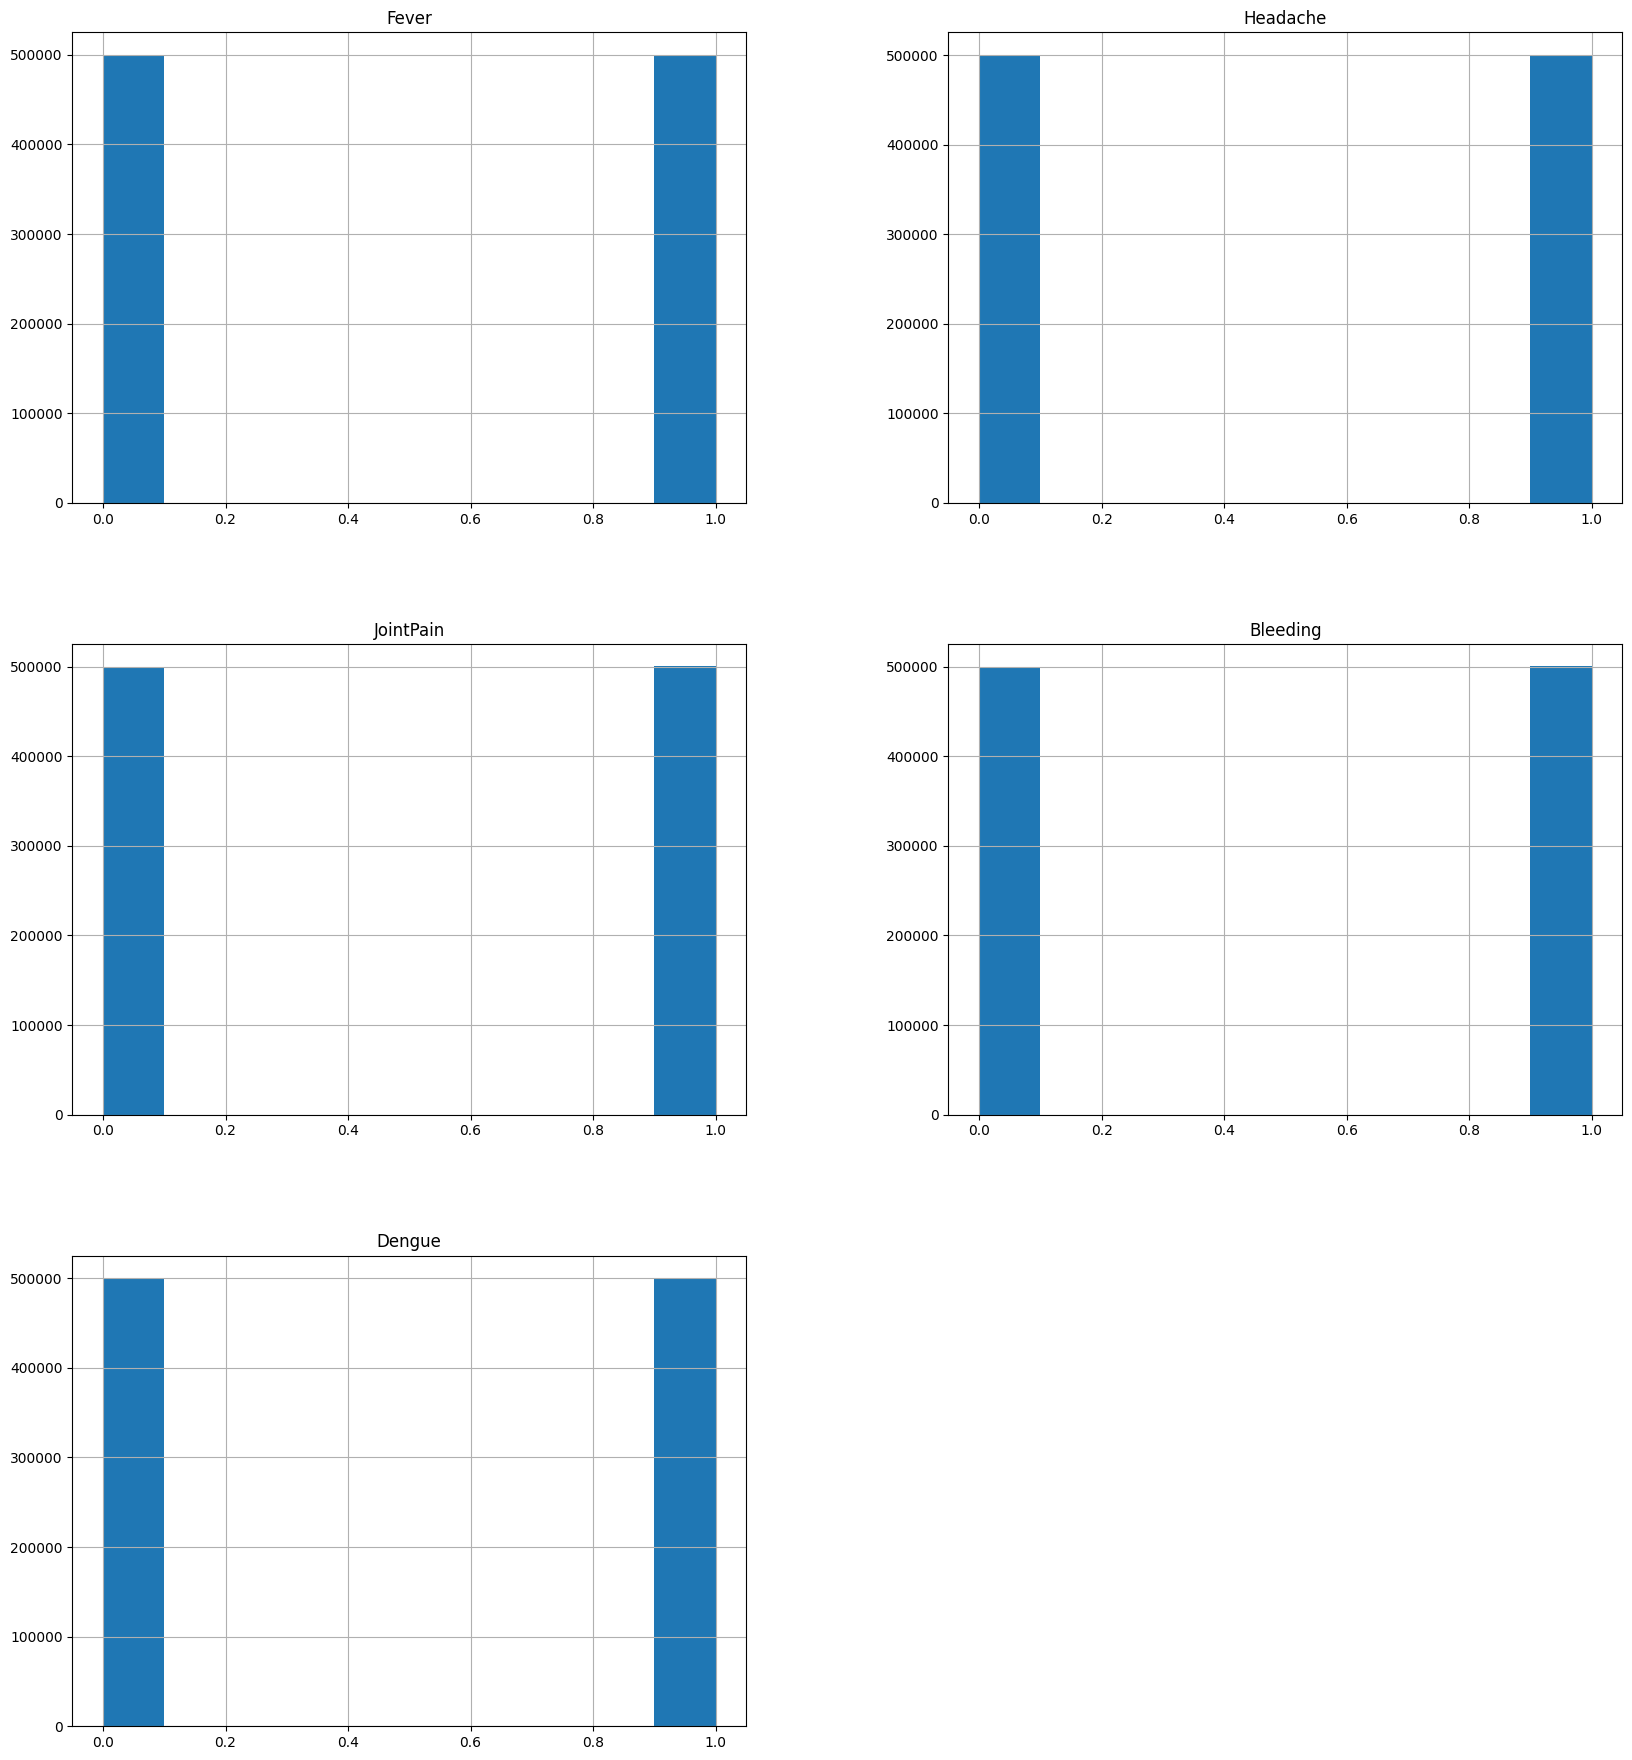

In [17]:
data.hist(figsize=(20, 22))
plt.show()

In [18]:
data.columns

Index(['Name', 'Fever', 'Headache', 'JointPain', 'Bleeding', 'Dengue'], dtype='object')

Correlation Matrix:


,Fever,Headache,JointPain,Bleeding,Dengue
Fever,1.000000,0.000897,0.000936,0.000072,0.001776
Headache,0.000897,1.000000,0.001191,-0.001609,0.000150
JointPain,0.000936,0.001191,1.000000,-0.000432,-0.000084
Bleeding,0.000072,-0.001609,-0.000432,1.000000,0.000444
Dengue,0.001776,0.000150,-0.000084,0.000444,1.000000


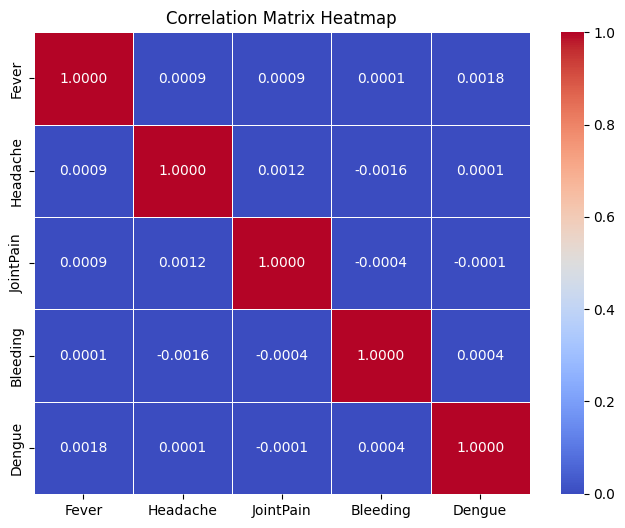

In [19]:
numeric_data = data.select_dtypes(include=[np.number])

correlation_matrix = numeric_data.corr()
print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [20]:
col1 = 'Fever'
col2 = 'Dengue'

specific_correlation = data[col1].corr(data[col2])
print(f"Correlation between '{col1}' and '{col2}': {specific_correlation:.6f}")

Correlation between 'Fever' and 'Dengue': 0.001776


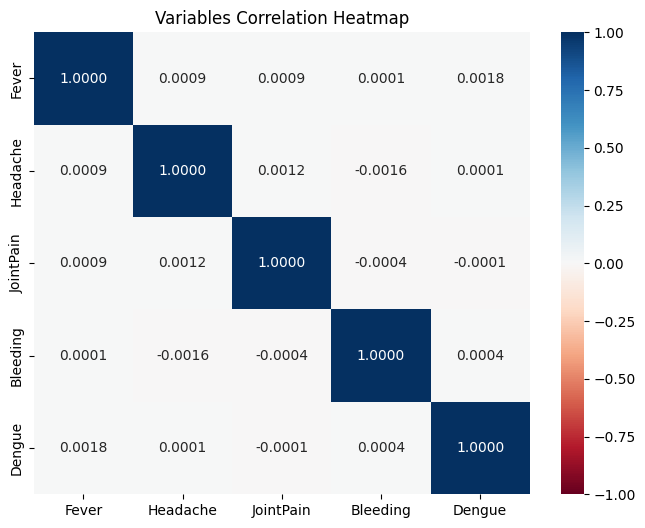

In [21]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu', vmin=-1, vmax=1, fmt='.4f')
plt.title('Variables Correlation Heatmap')
plt.show()

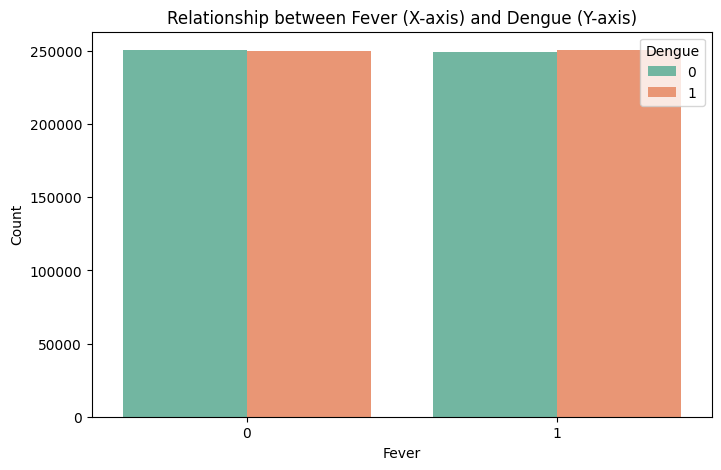

In [22]:
x_var = 'Fever'
y_var = 'Dengue'

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x=x_var, hue=y_var, palette='Set2')
plt.title(f'Relationship between {x_var} (X-axis) and {y_var} (Y-axis)')
plt.xlabel(x_var)
plt.ylabel('Count')
plt.legend(title=y_var)
plt.show()

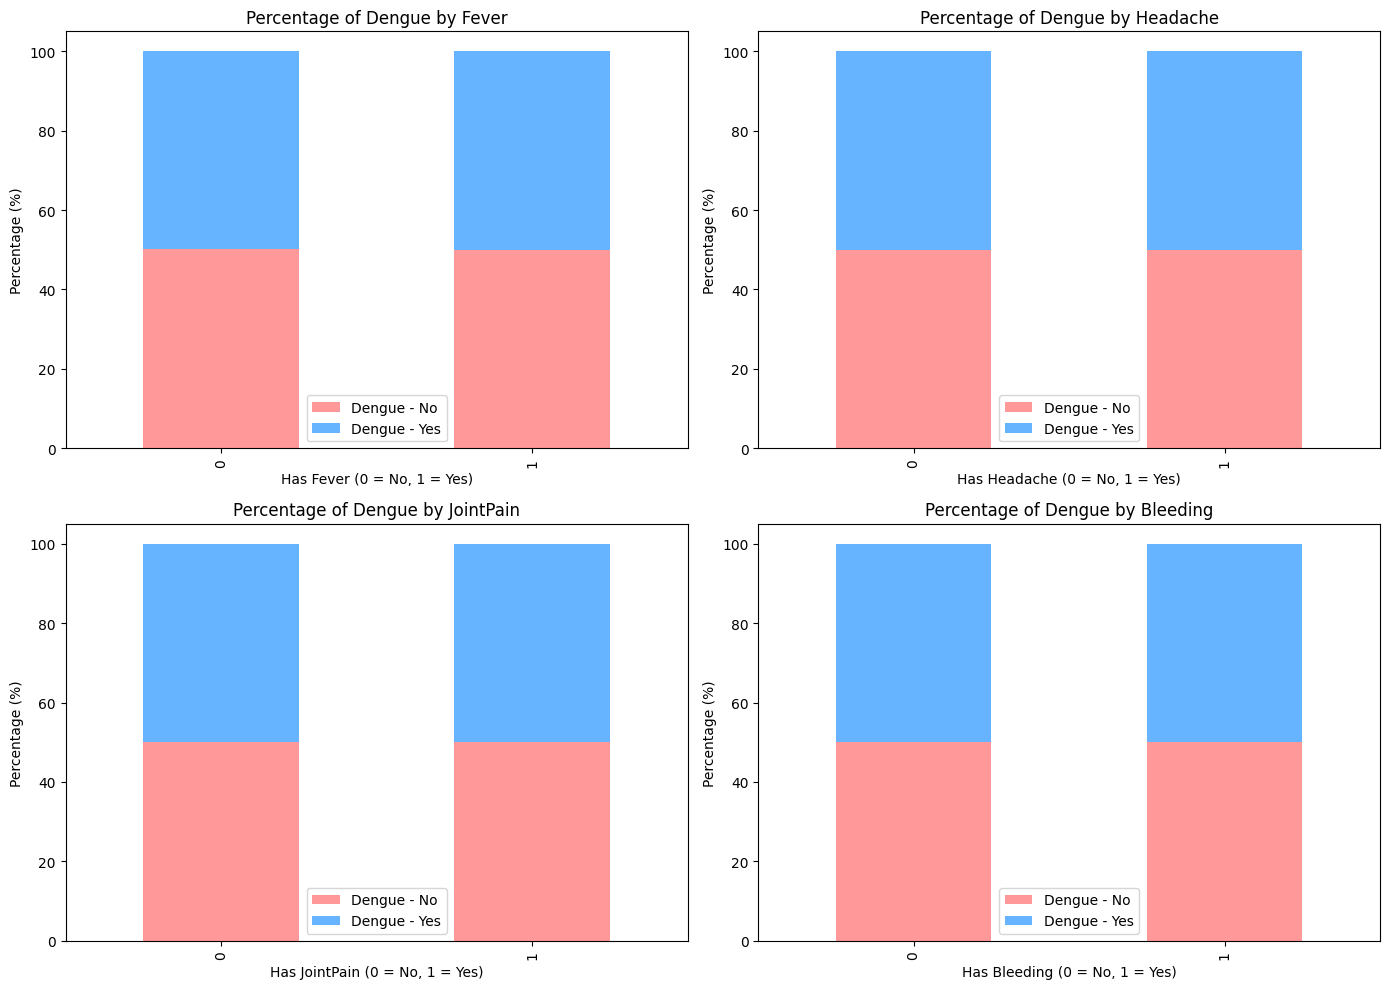

In [23]:
symptoms = ['Fever', 'Headache', 'JointPain', 'Bleeding']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, symptom in enumerate(symptoms):
    ct = pd.crosstab(data[symptom], data['Dengue'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, color=['#ff9999','#66b3ff'], ax=axes[i])
    axes[i].set_title(f'Percentage of Dengue by {symptom}')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(f'Has {symptom} (0 = No, 1 = Yes)')
    axes[i].legend(['Dengue - No', 'Dengue - Yes'])

plt.tight_layout()
plt.show()

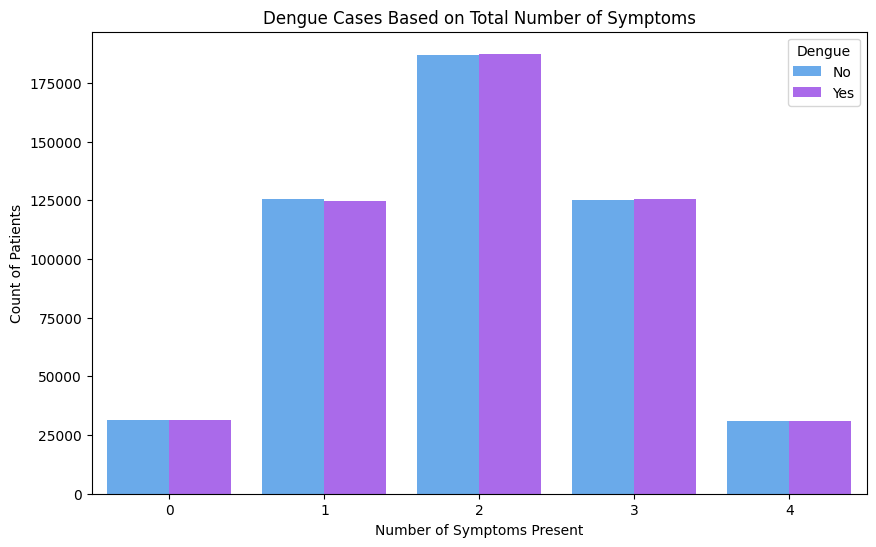

In [24]:
data['Total_Symptoms'] = data[symptoms].sum(axis=1)

plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='Total_Symptoms', hue='Dengue', palette='cool')
plt.title('Dengue Cases Based on Total Number of Symptoms')
plt.xlabel('Number of Symptoms Present')
plt.ylabel('Count of Patients')
plt.legend(title='Dengue', labels=['No', 'Yes'])
plt.show()

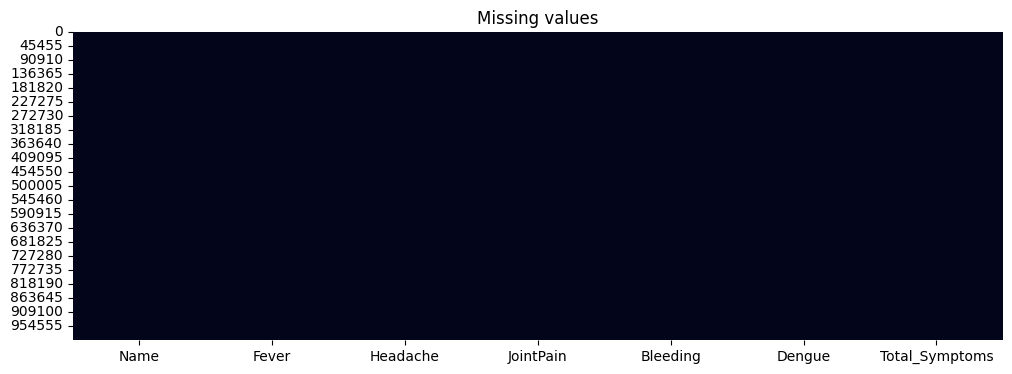

In [25]:
plt.figure(figsize=(12,4))
sns.heatmap(data.isna(), cbar=False)
plt.title("Missing values")
plt.show()